# Decorrelation Scale Analysis per Basin
This notebook replicates the calculation from `step3_decorrelation_scale_analysis/40_calculate_decorrelation_scale_per_bay.py` for all basins and compares the results.

In [1]:
import sys
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial.distance import cdist
from scipy.optimize import curve_fit
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature

warnings.filterwarnings('ignore')

# Setup paths
import os
sys.path.insert(0, os.path.abspath('..'))

from utils.data_loader import load_and_process_data
from utils.paths import ProjectPaths
from utils.mapping_config import MappingConfig

# Load Data
ProjectPaths.ensure_directories()
merged_gdf = load_and_process_data(force_reload=False)

# Get season and layer
step1_param_file = ProjectPaths.PROJECT_ROOT / "step1_data_processing_cleaning" / "step1_parameter.csv"
step1_params = {}
if step1_param_file.exists():
    df_p = pd.read_csv(step1_param_file)
    for _, row in df_p.iterrows():
        step1_params[row['parameter_name']] = row['value']
season = step1_params.get('season', 'Summer')
layer = step1_params.get('layer', 'bottom')

# Load yearly DO data
yearly_do_file = ProjectPaths.get_subset_dir(season, layer) / "yearly_do_df.csv"
yearly_do_df = pd.read_csv(yearly_do_file, index_col=0)
yearly_do_df.index = yearly_do_df.index.astype(str).str.zfill(8)


Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...


In [2]:
def gaussian_model_with_offset(x, A, dx):
    B = 1 - A
    return A * np.exp(-(x / dx)**2) + B

def calculate_r_crit(n, alpha=0.01):
    if n < 3:
        return 1.0
    df = n - 2
    t_crit = stats.t.ppf(1 - alpha/2, df)
    r_crit = np.sqrt(t_crit**2 / (t_crit**2 + df))
    return r_crit

def count_neighbors_within_distance(target_station, dist_matrix, max_distance_km=100):
    distances = dist_matrix.loc[target_station]
    neighbors = distances[(distances > 0) & (distances <= max_distance_km)]
    return len(neighbors)

def compute_decorrelation_for_division(division, yearly_do_df, merged_gdf):
    print(f"\nProcessing decorrelation scales for {division}...")
    
    db_division = division
    if division in ['Ise Mikawa Bay', 'Ise-Mikawa Bay']:
        db_division = 'Ise Bay'
        
    division_stations = merged_gdf[
        (merged_gdf['watermass_name'] == db_division) | 
        (merged_gdf['division'] == db_division)
    ]['zettaicode'].unique()
    
    division_stations_str = [str(st).zfill(8) for st in division_stations]
    yearly_do_df_div = yearly_do_df[yearly_do_df.index.isin(division_stations_str)].copy()
    
    if yearly_do_df_div.empty:
        print(f"No station data found for {division}.")
        return pd.DataFrame()
        
    min_periods = 15
    r_crit_alpha = 0.01
    distance_cutoff_km = 100
    
    station_coords = merged_gdf[['zettaicode', 'geometry']].drop_duplicates('zettaicode')
    station_coords['zettaicode_str'] = station_coords['zettaicode'].astype(str).str.zfill(8)
    station_coords = station_coords[station_coords['zettaicode_str'].isin(yearly_do_df_div.index)]
    station_coords = station_coords.set_index('zettaicode_str')
    
    if len(station_coords) < 5:
        print(f"Too few stations ({len(station_coords)}) in {division} for fitting. Skipping.")
        return pd.DataFrame()
        
    stns_utm = gpd.GeoDataFrame(station_coords, geometry='geometry', crs=merged_gdf.crs)
    stns_utm = stns_utm.to_crs(epsg=32653)
    
    coords = np.array([(geom.x, geom.y) for geom in stns_utm['geometry']])
    dist_matrix = cdist(coords, coords) / 1000.0
    dist_matrix_km = pd.DataFrame(dist_matrix, index=stns_utm.index, columns=stns_utm.index)
    
    results_list = []
    for target_station in yearly_do_df_div.index:
        target_series = yearly_do_df_div.loc[target_station]
        correlations = yearly_do_df_div.corrwith(target_series, axis=1, drop=True)
        
        valid_stats = []
        for neighbor in yearly_do_df_div.index:
            neigh_series = yearly_do_df_div.loc[neighbor]
            valid_count = pd.concat([target_series, neigh_series], axis=1).dropna().shape[0]
            
            if valid_count >= min_periods:
                if neighbor == target_station:
                    corr_val = 1.0
                    dist_val = 0.0
                else:
                    corr_val = correlations[neighbor]
                    dist_val = dist_matrix_km.loc[target_station, neighbor]
                
                if not np.isnan(corr_val) and not np.isnan(dist_val):
                    if dist_val <= distance_cutoff_km:
                        valid_stats.append({'dist': dist_val, 'corr': corr_val, 'n': valid_count})
        
        df_fit = pd.DataFrame(valid_stats)
        if len(df_fit) < 5:
            continue
            
        x_data = df_fit['dist'].values
        y_data = df_fit['corr'].values
        
        try:
            popt, pcov = curve_fit(
                gaussian_model_with_offset, x_data, y_data,
                p0=[1.0, 50.0], bounds=([0, 0.001], [2.0, np.inf])
            )
            A_fit, dx_fit_param = popt
            B_fit = 1 - A_fit
            
            n_neighbors_100km = count_neighbors_within_distance(
                target_station, dist_matrix_km, max_distance_km=distance_cutoff_km
            )
            
            if n_neighbors_100km >= 2:
                r_crit = calculate_r_crit(n_neighbors_100km, alpha=r_crit_alpha)
            else:
                avg_n = df_fit['n'].mean()
                r_crit = calculate_r_crit(avg_n, alpha=r_crit_alpha)
            
            if A_fit > 0 and (r_crit - B_fit) / A_fit > 0:
                inner_val = (r_crit - B_fit) / A_fit
                if inner_val < 1:
                    decorrelation_scale = dx_fit_param * np.sqrt(-np.log(inner_val))
                else:
                    decorrelation_scale = 0.0
            else:
                decorrelation_scale = 0.0
            
            residuals = y_data - gaussian_model_with_offset(x_data, *popt)
            ss_res = np.sum(residuals**2)
            ss_tot = np.sum((y_data - np.mean(y_data))**2)
            r_squared = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0
            
            results_list.append({
                'Station_ID': target_station,
                'Decorrelation_Scale_km': decorrelation_scale,
                'Amplitude_A': A_fit,
                'Offset_B': B_fit,
                'dx_param': dx_fit_param,
                'R_squared': r_squared,
                'r_crit': r_crit,
                'n_neighbors_100km': n_neighbors_100km
            })
        except Exception as e:
            pass
            
    results_df = pd.DataFrame(results_list)
    return results_df


In [3]:
divisions = ['Tokyo Bay', 'Ise Bay', 'Osaka Bay', 'Seto Inland Sea']
all_results = []

for div in divisions:
    res_df = compute_decorrelation_for_division(div, yearly_do_df, merged_gdf)
    if not res_df.empty:
        res_df['Basin'] = div
        all_results.append(res_df)

if all_results:
    final_df = pd.concat(all_results, ignore_index=True)
    # Filter out 0 decorrelation scale as they might represent failed fits
    final_df_valid = final_df[final_df['Decorrelation_Scale_km'] > 0]
    display(final_df_valid.groupby('Basin')['Decorrelation_Scale_km'].describe())



Processing decorrelation scales for Tokyo Bay...

Processing decorrelation scales for Ise Bay...

Processing decorrelation scales for Osaka Bay...

Processing decorrelation scales for Seto Inland Sea...


,count,mean,std,min,25%,50%,75%,max
Basin,,,,,,,,
Ise Bay,33.0,7.048572,3.076195,0.031354,4.988060,6.742844,9.633058,12.566379
Osaka Bay,10.0,3.462445,2.851488,0.000465,1.010311,3.757980,4.779910,9.441507
Seto Inland Sea,124.0,13.647777,9.030812,0.019127,7.765456,13.159536,19.824697,40.911314
Tokyo Bay,28.0,5.740963,3.339147,0.233304,3.930740,4.861708,7.802705,12.885018


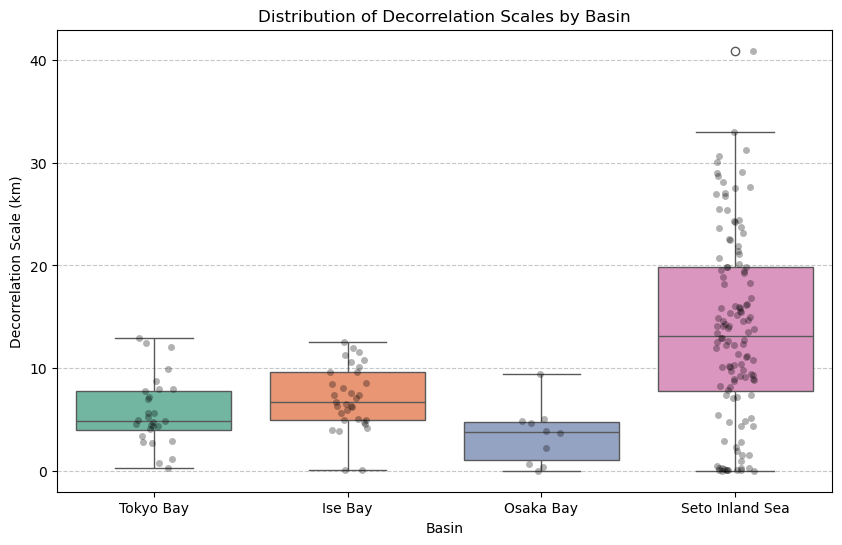

In [4]:
# Boxplot of Decorrelation Scales by Basin
plt.figure(figsize=(10, 6))
sns.boxplot(data=final_df_valid, x='Basin', y='Decorrelation_Scale_km', palette='Set2')
sns.stripplot(data=final_df_valid, x='Basin', y='Decorrelation_Scale_km', color='black', alpha=0.3, jitter=True)
plt.title('Distribution of Decorrelation Scales by Basin')
plt.ylabel('Decorrelation Scale (km)')
plt.xlabel('Basin')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


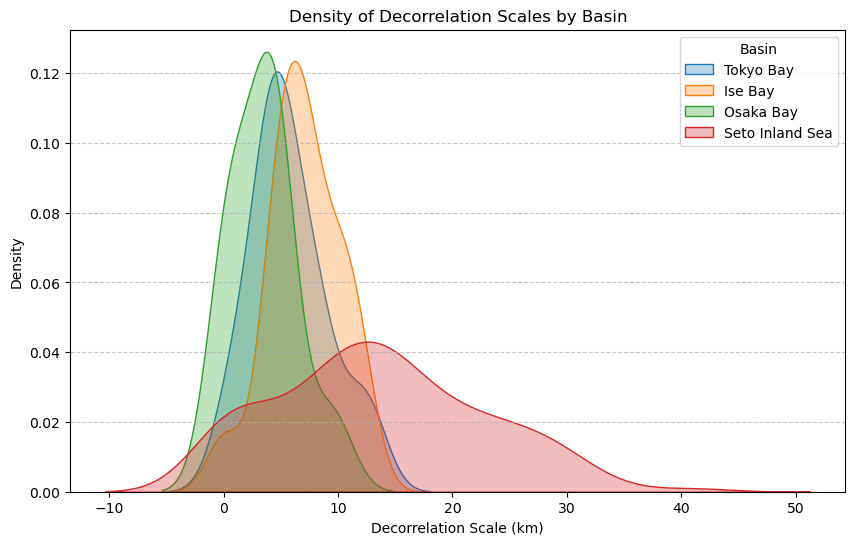

In [5]:
# KDE Plot to see the density
plt.figure(figsize=(10, 6))
for basin in final_df_valid['Basin'].unique():
    subset = final_df_valid[final_df_valid['Basin'] == basin]
    sns.kdeplot(subset['Decorrelation_Scale_km'], label=basin, fill=True, alpha=0.3)
plt.title('Density of Decorrelation Scales by Basin')
plt.xlabel('Decorrelation Scale (km)')
plt.ylabel('Density')
plt.legend(title='Basin')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


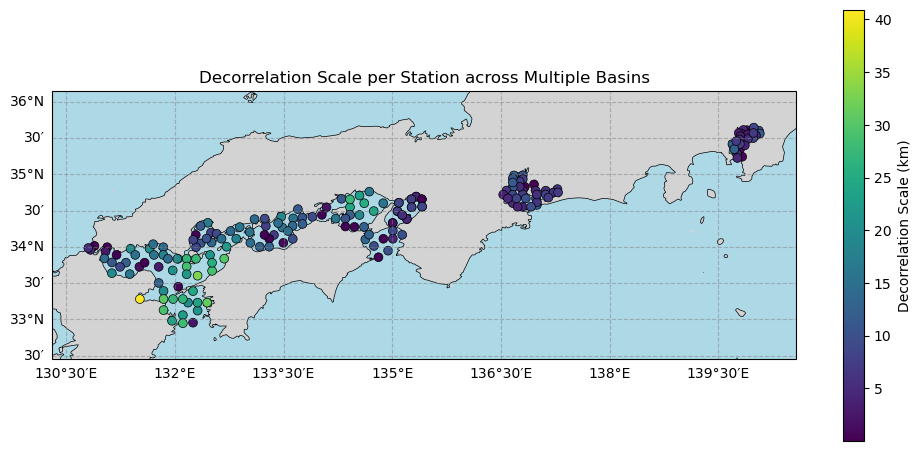

In [6]:
# Map visualization combining all basins
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_facecolor(MappingConfig.COLOR_OCEAN)
ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=1)

station_coords = merged_gdf[['zettaicode', 'latitude', 'longitude']].drop_duplicates('zettaicode')
station_coords['zettaicode_str'] = station_coords['zettaicode'].astype(str).str.zfill(8)

plot_data = station_coords.merge(final_df_valid, left_on='zettaicode_str', right_on='Station_ID')

min_lon, max_lon = plot_data['longitude'].min() - 0.5, plot_data['longitude'].max() + 0.5
min_lat, max_lat = plot_data['latitude'].min() - 0.5, plot_data['latitude'].max() + 0.5
ax.set_extent([min_lon, max_lon, min_lat, max_lat], crs=ccrs.PlateCarree())

sc = ax.scatter(
    plot_data['longitude'], plot_data['latitude'],
    c=plot_data['Decorrelation_Scale_km'],
    cmap='viridis', s=40, edgecolors='k', linewidths=0.5,
    transform=ccrs.PlateCarree(), zorder=2
)

cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.7)
cbar.set_label('Decorrelation Scale (km)')

gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False

plt.title('Decorrelation Scale per Station across Multiple Basins')
plt.show()


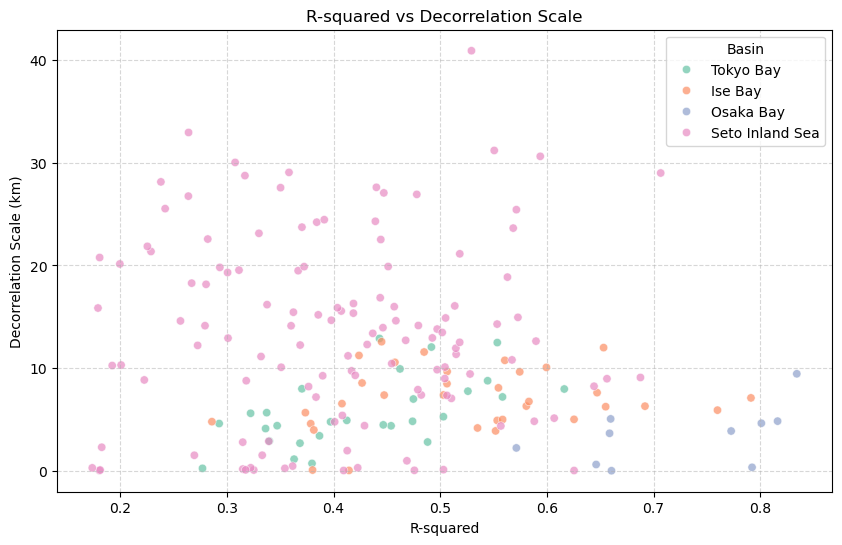

In [7]:
# Scatter plot of R-squared vs Decorrelation Scale
plt.figure(figsize=(10, 6))
sns.scatterplot(data=final_df_valid, x='R_squared', y='Decorrelation_Scale_km', hue='Basin', palette='Set2', alpha=0.7)
plt.title('R-squared vs Decorrelation Scale')
plt.xlabel('R-squared')
plt.ylabel('Decorrelation Scale (km)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()
